# Text Mining AI Patents with Spark NLP and Spark MLlib

This notebook walks through a complete, scalable text-analytics workflow on US AI-related patents (`ai_patents`, a Google Patents extract of ~668K patents filed 1955–2020).

> **Demo mode:** to keep it fast we only use the **first `n_rows` = 1,000 patents**. The code is exactly what you would run on the full table: raise `n_rows` (or set it to `None`) and the same pipeline scales out.

| Part | Package | What we do |
|---|---|---|
| 1. Explore & prepare | Spark SQL | Read nested Parquet, flatten arrays of structs, profile the corpus |
| 2. Linguistic preprocessing | **Spark NLP** | Annotator pipeline: tokenize → normalize → lemmatize → remove (domain) stop words; LightPipeline; YAKE keyword extraction |
| 3a. Topic modeling | **MLlib** | `CountVectorizer` + `LDA`, choosing *k* with held-out perplexity, topics vs. CPC classes |
| 3b. Word embeddings | **MLlib** | `Word2Vec` – which words live near *neural*, *speech*, *vehicle*? |
| 3c. Classification | **MLlib** | Predict a patent's CPC technology class from its abstract: `Pipeline`, TF-IDF, `LogisticRegression`, `CrossValidator`, evaluation |
| 3d. Semantic clustering & search | **Spark NLP + MLlib** | Pretrained BERT sentence embeddings → `KMeans` (silhouette) → `BucketedRandomProjectionLSH` nearest-neighbour search |

**Big idea:** every step is a *transformer* on a distributed DataFrame. Spark NLP annotators and MLlib stages share the same `Pipeline` API, so the identical code runs on a laptop or a cluster.

**Running it.** Use the course container (`hanisaf/teaching_container_amd64`), started from the folder that contains `ai_patents/`. The container ships PySpark 4.x; the next cell installs the matching Spark NLP (7.x) if it is missing. The first start downloads the Spark NLP jars and two small pretrained models (~45 MB), so you need internet access.
Runtime with `n_rows = 1000`: a few minutes, mostly Spark start-up and model downloads.

In [1]:
import sys, os, subprocess

In [2]:
# Spark NLP is not part of the base container: install it on first use.
# Spark NLP 7.x works with Spark 4.x (Scala 2.13); Spark NLP 5.x/6.x need Spark 3.x.
try:
    import sparknlp
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "spark-nlp==7.0.0"])
    import sparknlp


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [12]:
# notebook parameters, will be replaced by script arguments
application_name = "Spark NLP + MLlib on AI patents"
input_file_1 = r"/app/data/ai_patents"          # folder of Parquet files
output_file_1 = "nlp_mllib_demo"     # results are written here
n_rows = 1000                        # demo: first N patents only (None = all ~668K)
seed = 42
driver_memory = "16G"

In [5]:
# test if the script is running as a standalone program or a notebook
if __name__ == '__main__' and '__file__' in globals():
    print("Running as a script")
    application_name = sys.argv[1]
    input_file_1 = sys.argv[2]
    output_file_1 = sys.argv[3]
    interactive = False
else:
    print("Running as a notebook")
    pv = !{sys.executable} --version
    print("Python version ", pv)
    interactive = True

Running as a notebook
Python version  ['Python 3.12.15']


**Imports.** Note `import pyspark.sql.functions as F` instead of `from pyspark.sql.functions import *`: the star-import silently replaces Python built-ins such as `round`, `sum`, `max` and `filter` with Spark column functions, a classic source of confusing errors.

In [6]:
import pyspark
import pyspark.sql.functions as F
from pyspark.sql import Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (CountVectorizer, IDF, StringIndexer, Word2Vec,
                                BucketedRandomProjectionLSH, Normalizer as VectorNormalizer)
from pyspark.ml.clustering import LDA, KMeans
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, ClusteringEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.functions import vector_to_array
from pyspark.ml.linalg import DenseVector

from sparknlp.base import DocumentAssembler, Finisher, EmbeddingsFinisher, LightPipeline
from sparknlp.annotator import (Tokenizer, Normalizer, LemmatizerModel, StopWordsCleaner,
                                YakeKeywordExtraction, BertSentenceEmbeddings)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pyspark.__version__, sparknlp.version()

('4.2.0', '7.0.0')

In [7]:
def show(df, n=20, truncate=True):
    if interactive:
        df.show(n, truncate=truncate)

### Start Spark with Spark NLP

`sparknlp.start()` is a thin wrapper around `SparkSession.builder`: it adds the Spark NLP jar (`spark.jars.packages`) that matches your Spark/Scala version and sets the Kryo serializer that Spark NLP needs. Everything else (master, memory, UI port) comes from the container's `PYSPARK_SUBMIT_ARGS` or from `params`.

In [8]:
spark = sparknlp.start(memory=driver_memory,
                       params={"spark.app.name": application_name,
                               "spark.sql.shuffle.partitions": "64"})
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext
spark

:: loading settings :: url = jar:file:/usr/local/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
com.johnsnowlabs.nlp#spark-nlp_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-fb8dae70-9c23-4e79-af8a-d9ebd584f73f;1.0
	confs: [default]
	found com.johnsnowlabs.nlp#spark-nlp_2.13;7.0.0 in central
	found com.typesafe#config;1.4.2 in central
	found org.rocksdb#rocksdbjni;6.29.5 in central
	found com.amazonaws#aws-java-sdk-s3;1.12.500 in central
	found com.amazonaws#aws-java-sdk-kms;1.12.500 in central
	found com.amazonaws#aws-java-sdk-core;1.12.500 in central
	found commons-logging#commons-logging;1.1.3 in central
	found commons-codec#commons-codec;1.15 in central
	found org.apache.httpcomponents#httpclient;4.5.13 in central
	found org.apache.httpcomponents#httpcore;4.4.13 in central
	foun

---
## Part 1 – Explore and prepare the data

The raw table has 70 columns; many are **arrays of structs** (`abstract_localized`, `cpc`, `assignee_harmonized`, ...). Parquet is columnar, so selecting only the columns we need means Spark never reads the (huge) full-text `description` and `claims` columns from disk.

In [13]:
raw = spark.read.parquet(input_file_1)
raw.printSchema()
raw.count()

root
 |-- publication_number: string (nullable = true)
 |-- application_number: string (nullable = true)
 |-- country_code: string (nullable = true)
 |-- kind_code: string (nullable = true)
 |-- application_kind: string (nullable = true)
 |-- application_number_formatted: string (nullable = true)
 |-- pct_number: string (nullable = true)
 |-- family_id: string (nullable = true)
 |-- spif_publication_number: string (nullable = true)
 |-- spif_application_number: string (nullable = true)
 |-- title_localized: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- text: string (nullable = true)
 |    |    |-- language: string (nullable = true)
 |    |    |-- truncated: boolean (nullable = true)
 |-- abstract_localized: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- text: string (nullable = true)
 |    |    |-- language: string (nullable = true)
 |    |    |-- truncated: boolean (nullable = true)
 |-- claims_localized:

667889

In [15]:
r = raw.first()
r

Row(publication_number='US-9582377-B1', application_number='US-201514663005-A', country_code='US', kind_code='B1', application_kind='A', application_number_formatted='US14663005', pct_number='', family_id='58056897', spif_publication_number='US9582377B1', spif_application_number='US201514663005', title_localized=[Row(text='Dynamic sizing of storage capacity for a remirror buffer', language='en', truncated=False)], abstract_localized=[Row(text='A remirror buffer can be used in failover situations so as to backup storage volumes in a service provider. The remirror buffer is dynamically resized to meet current usage metrics captured from a data center. A risk boundary can be defined through which resource hosts are grouped together so as to determine the usage metrics. The risk boundary can be based on a topology of the data center, such as a room/rack/sharing of power supplies, or other characteristics of the resource hosts.', language='en', truncated=False)], claims_localized=[Row(text=

In [16]:
if n_rows:
    raw = raw.limit(n_rows)   # demo mode: first n_rows records
raw.select("publication_number", "filing_date", "abstract_localized", "cpc", "assignee_harmonized").printSchema()

root
 |-- publication_number: string (nullable = true)
 |-- filing_date: long (nullable = true)
 |-- abstract_localized: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- text: string (nullable = true)
 |    |    |-- language: string (nullable = true)
 |    |    |-- truncated: boolean (nullable = true)
 |-- cpc: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- code: string (nullable = true)
 |    |    |-- inventive: boolean (nullable = true)
 |    |    |-- first: boolean (nullable = true)
 |    |    |-- tree: array (nullable = true)
 |    |    |    |-- element: string (containsNull = true)
 |-- assignee_harmonized: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- name: string (nullable = true)
 |    |    |-- country_code: string (nullable = true)



**Flattening nested data with higher-order functions.** `filter(array, x -> predicate)` keeps matching structs, `transform(array, x -> expr)` maps over them, and `get(array, 0)` takes the first element.
We use `get(...)` rather than `array[0]` on purpose: Spark 4 runs in **ANSI mode** by default, and `array[0]` on an empty array raises an error instead of returning `NULL`.

We derive:
* `abstract`: the English abstract text
* `filing_year`: from the `yyyymmdd` integer
* `cpc_subclass`: the 4-character Cooperative Patent Classification subclass of the *first* (primary) CPC code, e.g. `G06T` = image processing
* `cpc_section`: its first letter (A–H, Y)

In [17]:
patents = (raw
    .select(
        "publication_number",
        (F.col("filing_date") / 10000).cast("int").alias("filing_year"),
        F.expr("get(filter(title_localized, t -> t.language = 'en'), 0).text").alias("title"),
        F.expr("get(filter(abstract_localized, a -> a.language = 'en'), 0).text").alias("abstract"),
        F.expr("get(filter(cpc, c -> c.first), 0).code").alias("cpc_first"),
        F.expr("get(assignee_harmonized, 0).name").alias("assignee"))
    .withColumn("cpc_subclass", F.substring("cpc_first", 1, 4))
    .withColumn("cpc_section", F.substring("cpc_first", 1, 1))
    .filter(F.col("abstract").isNotNull() & F.col("cpc_first").isNotNull()))
patents = patents.repartition(16).cache()
print(f"{patents.count():,} patents with an English abstract and a CPC code")
show(patents.select("publication_number", "filing_year", "cpc_subclass", "assignee", "title"), 5, truncate=60)

[Stage 6:======================================================>(406 + 1) / 407]

1,000 patents with an English abstract and a CPC code
+------------------+-----------+------------+-----------------------+------------------------------------------------------------+
|publication_number|filing_year|cpc_subclass|               assignee|                                                       title|
+------------------+-----------+------------+-----------------------+------------------------------------------------------------+
|     US-8732274-B2|       2011|        H04L|          BOUAZIZI IMED|Method and apparatus for generating and handling streamin...|
|     US-8504995-B2|       2007|        G06F|              NEFT MARK|        Process flow analysis  based on processing artifacts|
|    US-10657725-B2|       2018|        G06T|     FLOW IMMERSIVE INC|                   Augmented virtual reality object creation|
|     US-8838657-B1|       2012|        G06F|         MALONE JAMES A|          Document fingerprints using block encoding of text|
|     US-7103635-B2|       20

/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


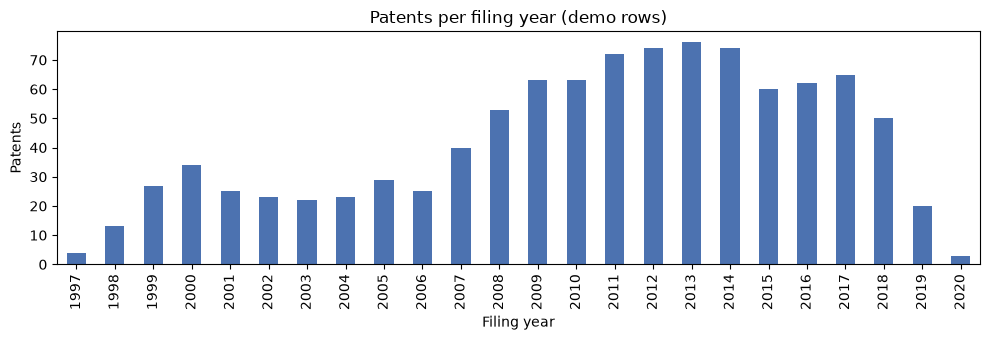

In [18]:
by_year = patents.groupBy("filing_year").count().orderBy("filing_year").toPandas()
ax = by_year.plot(x="filing_year", y="count", kind="bar", figsize=(10, 3.5), legend=False, color="#4C72B0")
ax.set_xlabel("Filing year"); ax.set_ylabel("Patents"); ax.set_title("Patents per filing year (demo rows)")
plt.tight_layout(); plt.show()

**Careful:** `limit(n)` returns the *first* rows Spark reads, not a random sample. Here they happen to be spread over many years, but nothing guarantees that. For a representative subset, use `raw.sample(fraction=..., seed=...)`. On the full table, filings grow roughly exponentially until about 2015 and then appear to drop. That drop is a **data artifact** (right-censoring: patents are published ~18 months after filing and granted years later), not a collapse of AI patenting.

In [19]:
SUBCLASS_NAMES = {
    "G06F": "Digital data processing", "G06Q": "Business / admin data processing",
    "H04L": "Digital transmission / networking", "H04N": "Video & image communication",
    "G06T": "Image processing", "A61B": "Medical diagnosis", "G10L": "Speech processing",
    "H04W": "Wireless networks", "G06V": "Image & video recognition", "G06N": "AI / ML computing models",
    "H04M": "Telephony", "G06K": "Data recognition (legacy)", "G05B": "Control systems",
    "B60W": "Vehicle control", "G01S": "Radar / sonar / lidar"}
name_udf = F.udf(lambda c: SUBCLASS_NAMES.get(c, ""))

n_patents = patents.count()
top_subclasses = (patents.groupBy("cpc_subclass").count()
                  .withColumn("share", F.round(F.col("count") / n_patents * 100, 1))
                  .withColumn("description", name_udf("cpc_subclass"))
                  .orderBy(F.desc("count")))
show(top_subclasses, 15)

/usr/local/lib/python3.12/site-packages/pyspark/sql/udf.py:116: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/site-packages/pyspark/sql/udf.py:120: RuntimeWarning: Arrow optimization failed to enable because PyArrow or Pandas is not installed. Falling back to a non-Arrow-optimized UDF.
  warnings.warn(
[Stage 51:>                                                         (0 + 1) / 1]

+------------+-----+-----+--------------------+
|cpc_subclass|count|share|         description|
+------------+-----+-----+--------------------+
|        G06F|  313| 31.3|Digital data proc...|
|        G06Q|  106| 10.6|Business / admin ...|
|        H04L|  102| 10.2|Digital transmiss...|
|        G06T|   55|  5.5|    Image processing|
|        H04N|   49|  4.9|Video & image com...|
|        A61B|   28|  2.8|   Medical diagnosis|
|        G10L|   24|  2.4|   Speech processing|
|        H04W|   22|  2.2|   Wireless networks|
|        H04M|   19|  1.9|           Telephony|
|        G06V|   15|  1.5|Image & video rec...|
|        G01C|   13|  1.3|                    |
|        A63F|   12|  1.2|                    |
|        H04B|   11|  1.1|                    |
|        G06K|    9|  0.9|Data recognition ...|
|        G09B|    9|  0.9|                    |
+------------+-----+-----+--------------------+
only showing top 15 rows


In [20]:
lengths = patents.select(F.size(F.split("abstract", r"\s+")).alias("words"))
show(lengths.summary("mean", "stddev", "min", "25%", "50%", "75%", "max"))

+-------+-----------------+
|summary|            words|
+-------+-----------------+
|   mean|          117.264|
| stddev|38.35290405235631|
|    min|               18|
|    25%|               90|
|    50%|              119|
|    75%|              143|
|    max|              302|
+-------+-----------------+



Abstracts are short (typically 100–150 words) and fairly uniform: a good unit of analysis for topic models and embeddings.

In [21]:
corpus = patents
print(f"{corpus.count():,} patents in the working set")

1,000 patents in the working set


---
## Part 2 – Linguistic preprocessing with Spark NLP

Spark NLP (John Snow Labs) brings production NLP to Spark. Its building blocks:

* **Annotators** turn input columns into *annotation* columns. Each annotation is a struct `(annotatorType, begin, end, result, metadata, embeddings)`, so every token still knows its character offsets in the original text.
* **Approaches vs. Models**: like MLlib estimators vs. transformers. Some annotators are trained (`*Approach`), others are rule-based or **pretrained** and downloaded from the models hub (`*.pretrained()`).
* `DocumentAssembler` is the entry point (raw string → `document` annotation); `Finisher` is the exit point (annotations → plain Spark arrays for MLlib).

### Why the extra stop words?
Patent language is formulaic. A topic model trained on raw patent text spends most of its capacity on legal boilerplate: *wherein, claim, comprise, said, plurality, first, second, ...*.
Lemmatization also creates odd survivors: *further* becomes **far**, *according* becomes **accord**, *based* becomes **base**.
We remove these with a **domain stop-word list** on top of the standard English list, and we apply it *after* lemmatization so that one entry (`comprise`) covers *comprises, comprising, comprised*.

In [22]:
patent_stopwords = (
    "wherein whereby thereof therein thereto herein hereby said say claim claims comprise include contain consist "
    "method methods system systems apparatus device devices means unit module process "
    "first second third plurality least one two multiple various respective "
    "base accord far associate provide use configure perform determine generate receive "
    "embodiment invention present disclose describe example aspect may also via set within"
).split()

english_stopwords = StopWordsCleaner.loadDefaultStopWords("english")
print(len(english_stopwords), "English stop words +", len(patent_stopwords), "patent stop words")

181 English stop words + 59 patent stop words


In [23]:
document = DocumentAssembler().setInputCol("abstract").setOutputCol("document")

tokenizer = Tokenizer().setInputCols(["document"]).setOutputCol("token")

normalizer = (Normalizer().setInputCols(["token"]).setOutputCol("normalized")
              .setLowercase(True)
              .setCleanupPatterns(["[^A-Za-z]"])    # keep letters only (drops numbers, punctuation)
              .setMinLength(3))

lemmatizer = (LemmatizerModel.pretrained("lemma_antbnc", "en")   # pretrained, ~1 MB
              .setInputCols(["normalized"]).setOutputCol("lemma"))

stopwords = (StopWordsCleaner().setInputCols(["lemma"]).setOutputCol("clean_lemma")
             .setStopWords(english_stopwords + patent_stopwords)
             .setCaseSensitive(False))

finisher = (Finisher().setInputCols(["clean_lemma"]).setOutputCols(["lemmas"])
            .setOutputAsArray(True).setCleanAnnotations(False))

nlp_pipeline = Pipeline(stages=[document, tokenizer, normalizer, lemmatizer, stopwords, finisher])
nlp_model = nlp_pipeline.fit(corpus)   # nothing is trained here; fit() just assembles the PipelineModel

lemma_antbnc download started this may take some time.
Approximate size to download 907.6 KB
[ | ]lemma_antbnc download started this may take some time.
Approximate size to download 907.6 KB
Download done! Loading the resource.
[OK!]


**What does an annotation look like?** Each row now carries one annotation column per stage. Here are the first few tokens of one abstract with their character offsets:

In [24]:
one = nlp_model.transform(corpus.limit(1))
show(one.select(F.explode(F.slice("token", 1, 6)).alias("t"))
        .select("t.annotatorType", "t.begin", "t.end", "t.result"), truncate=False)
show(one.select(F.slice("token.result", 1, 25).alias("tokens"),
                F.slice("lemmas", 1, 25).alias("lemmas")), truncate=False)

+-------------+-----+---+----------+
|annotatorType|begin|end|result    |
+-------------+-----+---+----------+
|token        |0    |6  |Various   |
|token        |8    |14 |methods   |
|token        |16   |18 |for       |
|token        |20   |29 |generating|
|token        |31   |33 |and       |
|token        |35   |42 |handling  |
+-------------+-----+---+----------+

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|tokens                                                                                                                                                                                               

**LightPipeline** runs the same fitted pipeline on plain Python strings *without* creating a DataFrame. That makes it useful for ad-hoc inspection, unit tests, and low-latency serving.

In [25]:
# (a Finisher at the end would hide the intermediate columns, so we drop it here)
light = LightPipeline(PipelineModel(stages=nlp_model.stages[:-1]))
result = light.annotate("The neural networks are trained on labeled images, wherein said images comprise "
                        "a plurality of pixels captured by first and second cameras.")
print("tokens:", result["token"])
print("lemmas:", result["lemma"])
print("clean :", result["clean_lemma"])

tokens: ['The', 'neural', 'networks', 'are', 'trained', 'on', 'labeled', 'images', ',', 'wherein', 'said', 'images', 'comprise', 'a', 'plurality', 'of', 'pixels', 'captured', 'by', 'first', 'and', 'second', 'cameras', '.']
lemmas: ['the', 'neural', 'network', 'be', 'train', 'label', 'image', 'wherein', 'say', 'image', 'comprise', 'plurality', 'pixel', 'capture', 'first', 'and', 'second', 'camera']
clean : ['neural', 'network', 'train', 'label', 'image', 'image', 'pixel', 'capture', 'camera']


Now apply the pipeline to the whole sample. Spark is **lazy**: nothing runs until an action (`count`). We cache the result because all later MLlib steps reuse it.

In [26]:
docs = (nlp_model.transform(corpus)
        .select("publication_number", "filing_year", "cpc_subclass", "abstract", "lemmas")
        .filter(F.size("lemmas") >= 10)
        .cache())
print(f"{docs.count():,} preprocessed abstracts")

top_lemmas = (docs.select(F.explode("lemmas").alias("lemma"))
              .groupBy("lemma").count().orderBy(F.desc("count")))
show(top_lemmas, 25)

998 preprocessed abstracts
+-----------+-----+
|      lemma|count|
+-----------+-----+
|       data| 1165|
|      image|  888|
|       user|  742|
|information|  553|
|     object|  391|
|application|  350|
|      value|  344|
|    network|  336|
|    content|  315|
|   identify|  307|
|    control|  281|
|   computer|  272|
|    display|  257|
|      store|  255|
|      model|  252|
|      input|  236|
|       time|  234|
|   location|  225|
|     select|  224|
|      event|  220|
|    request|  219|
|     signal|  217|
| correspond|  211|
|    program|  196|
|     memory|  195|
+-----------+-----+
only showing top 25 rows


The most frequent lemmas are now content words (*data, image, user, network, model, ...*) rather than boilerplate. If something generic still dominates, add it to `patent_stopwords` and re-run. **Preprocessing is iterative.**

### Bonus: unsupervised keyword extraction with YAKE
`YakeKeywordExtraction` scores candidate 1–3-word phrases using statistical features of a single document: position, frequency, casing, and how many different contexts a word appears in. No training and no external corpus are needed.

In [27]:
yake = (YakeKeywordExtraction().setInputCols(["token"]).setOutputCol("keywords")
        .setMinNGrams(1).setMaxNGrams(3).setNKeywords(5)
        .setStopWords(english_stopwords + patent_stopwords))
yake_pipeline = Pipeline(stages=[document, tokenizer, yake]).fit(corpus)

keywords = (yake_pipeline.transform(corpus.limit(8))
            .select("publication_number", "title",
                    # lower YAKE score = more relevant; sort (score, phrase) structs, keep the phrases
                    F.expr("array_distinct(transform(array_sort(transform(keywords, k -> struct(float(k.metadata.score) AS score, k.result AS phrase))), k -> k.phrase))").alias("keywords")))
show(keywords, truncate=70)

+------------------+----------------------------------------------------------------------+---------------------------------------------------------+
|publication_number|                                                                 title|                                                 keywords|
+------------------+----------------------------------------------------------------------+---------------------------------------------------------+
|     US-8732274-B2|Method and apparatus for generating and handling streaming media qu...|      [media, presentation, metrics, quality, experience]|
|     US-8504995-B2|                  Process flow analysis  based on processing artifacts|[processing artifacts, processing, artifacts, item, flow]|
|    US-10657725-B2|                             Augmented virtual reality object creation|           [avr, engine, avr object, object, avr objects]|
|     US-8838657-B1|                    Document fingerprints using block encoding of text|         

---
## Part 3a – Topic modeling with MLlib LDA

**Latent Dirichlet Allocation** assumes each document is a mixture of *k* topics and each topic is a distribution over words. MLlib's `LDA` needs **raw term counts** (not TF-IDF), which `CountVectorizer` produces:
* `vocabSize`: keep at most the 5,000 most frequent terms
* `minDF=5`: drop terms appearing in fewer than 5 documents (typos, rare jargon); use 20+ on the full data
* `maxDF=0.3`: drop terms appearing in more than 30% of documents (remaining corpus-specific stop words)

In [28]:
cv = CountVectorizer(inputCol="lemmas", outputCol="tf", vocabSize=5000, minDF=5, maxDF=0.3)
cv_model = cv.fit(docs)
vocab = cv_model.vocabulary
docs_tf = cv_model.transform(docs).cache()
print(f"vocabulary size: {len(vocab):,}")
print("most frequent:", vocab[:20])

vocabulary size: 1,149
most frequent: ['image', 'user', 'information', 'object', 'application', 'value', 'network', 'content', 'identify', 'control', 'computer', 'display', 'store', 'model', 'input', 'time', 'location', 'select', 'event', 'request']


### How many topics?
There is no single correct *k*. Two common criteria are:

* **Held-out perplexity** (computed natively by MLlib, lower is better) measures how well the model predicts *unseen* documents.
* **Topic coherence** (e.g., gensim's c_v) measures how often a topic's top words co-occur, a proxy for human interpretability.

They often disagree: on large corpora perplexity keeps improving with more topics while interpretability peaks early. Here we use perplexity with a train/test split. We fit with the `online` optimizer, which is fast and processes mini-batches.

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


k= 3  held-out log-perplexity = 7.0156
k= 5  held-out log-perplexity = 7.2877
k= 8  held-out log-perplexity = 7.8055
k=12  held-out log-perplexity = 8.6903
k=16  held-out log-perplexity = 9.6467


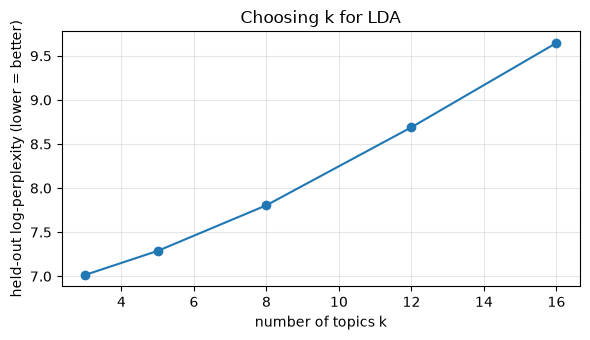

In [29]:
train_tf, test_tf = docs_tf.randomSplit([0.8, 0.2], seed=seed)
train_tf.cache(); test_tf.cache()

perplexity = {}
for k in [3, 5, 8, 12, 16]:
    m = LDA(k=k, maxIter=20, optimizer="online", featuresCol="tf", seed=seed).fit(train_tf)
    perplexity[k] = m.logPerplexity(test_tf)
    print(f"k={k:>2}  held-out log-perplexity = {perplexity[k]:.4f}")

plt.figure(figsize=(6, 3.5))
plt.plot(list(perplexity), list(perplexity.values()), marker="o")
plt.xlabel("number of topics k"); plt.ylabel("held-out log-perplexity (lower = better)")
plt.title("Choosing k for LDA"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

With only ~800 training abstracts, perplexity gets **worse** as *k* grows: extra topics add parameters the data cannot support (overfitting). On the full corpus the curve turns around. In both cases the final choice also depends on whether people can interpret the topics.

We pick a moderate *k* for interpretability (feel free to change it) and fit the final model on all documents in the sample.

In [30]:
n_topics = 8
lda_model = LDA(k=n_topics, maxIter=40, optimizer="online", featuresCol="tf", seed=seed).fit(docs_tf)

topics = lda_model.describeTopics(maxTermsPerTopic=10).collect()
topic_words = {r["topic"]: [vocab[i] for i in r["termIndices"]] for r in topics}
topic_label = {t: " / ".join(w[:3]) for t, w in topic_words.items()}
pd.set_option("display.max_colwidth", 120)
pd.DataFrame({"topic": list(topic_words), "top words": [", ".join(w) for w in topic_words.values()]})

,topic,top words
0,0,"image, object, region, point, detect, feature, input, area, information, location"
1,1,"user, information, event, network, access, service, identify, memory, control, request"
2,2,"content, node, text, media, call, application, interface, speech, list, cache"
3,3,"model, value, signal, state, channel, message, instruction, machine, learn, sample"
4,4,"application, network, analysis, frequency, link, test, time, computer, web, sequence"
5,5,"grid, loop, schedule, joint, analyze, line, primary, secondary, duration, cycle"
6,6,"value, vehicle, block, item, element, user, code, notification, control, time"
7,7,"resource, cell, security, mode, feedback, potential, wireless, power, transmission, engine"


### Do the topics line up with official technology classes?
`transform` gives every document a `topicDistribution` vector (its mixture of topics). Averaging these vectors by CPC subclass shows which topics dominate each official class. The topics were learned **without** the labels, so agreement is evidence that they are meaningful.
On the full data, the same `groupBy(...).agg(avg(...))` grouped by `filing_year` shows how topics trend over 40 years (see Exercise 5).

/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


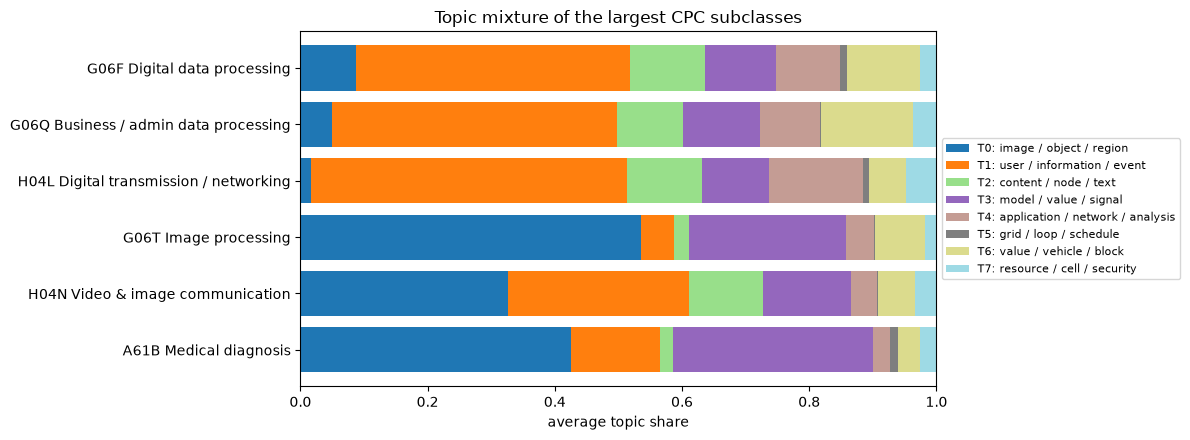

In [31]:
doc_topics = lda_model.transform(docs_tf).withColumn("theta", vector_to_array("topicDistribution"))

top_cpc = [r["cpc_subclass"] for r in
           docs.groupBy("cpc_subclass").count().orderBy(F.desc("count")).limit(6).collect()]
by_class = (doc_topics.filter(F.col("cpc_subclass").isin(top_cpc))
            .groupBy("cpc_subclass")
            .agg(*[F.avg(F.col("theta")[t]).alias(str(t)) for t in range(n_topics)])
            .toPandas().set_index("cpc_subclass").loc[top_cpc])
by_class.columns = [f"T{c}: {topic_label[int(c)]}" for c in by_class.columns]
by_class.index = [f"{c} {SUBCLASS_NAMES.get(c, '')}" for c in by_class.index]

ax = by_class.plot.barh(stacked=True, figsize=(12, 4.5), colormap="tab20", width=0.8)
ax.set_xlabel("average topic share"); ax.set_xlim(0, 1); ax.invert_yaxis()
ax.set_title("Topic mixture of the largest CPC subclasses")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout(); plt.show()

---
## Part 3b – Word embeddings with MLlib Word2Vec

`Word2Vec` learns a dense vector for every word so that words used in similar contexts are close together. This works on the same `lemmas` arrays, with no labels needed. `findSynonyms` returns the nearest words by cosine similarity, which shows the *patent-specific* meaning of a word. Word2Vec needs a lot of text: with 1,000 abstracts the neighbours are noisy, and they become much sharper on the full data.

In [32]:
w2v_model = Word2Vec(vectorSize=50, minCount=5, windowSize=5, maxIter=5, numPartitions=1,
                     seed=seed, inputCol="lemmas", outputCol="w2v").fit(docs)

for word in ["data", "image", "network", "user", "storage"]:
    try:
        syn = w2v_model.findSynonymsArray(word, 8)
        print(f"{word:>8}: " + ", ".join(f"{w} ({s:.2f})" for w, s in syn))
    except Exception:
        print(f"{word:>8}: not in vocabulary")

    data: assistance (0.45), inflight (0.44), database (0.44), storage (0.43), archive (0.43), retrieval (0.42), file (0.42), plural (0.42)
   image: composite (0.72), blur (0.68), align (0.67), respectively (0.66), foreground (0.65), searchtarget (0.65), multichannel (0.64), fig (0.64)
 network: reside (0.64), topology (0.59), subnetworks (0.58), intersection (0.57), destination (0.56), address (0.56), public (0.54), neural (0.52)
    user: interact (0.65), interface (0.62), default (0.61), selection (0.59), display (0.53), conversational (0.53), graphical (0.52), relevant (0.52)
 storage: medium (0.65), computerreadable (0.65), wide (0.64), nontransitory (0.59), chunk (0.58), media (0.54), embody (0.51), store (0.51)


---
## Part 3c – Supervised learning: predict the technology class

Can we tell **which technology domain** a patent belongs to from its abstract alone? The label is the primary CPC subclass. We keep the four most frequent subclasses in our rows and group the rest as `OTHER`.

**Class imbalance.** One class (usually G06F, general data processing) dominates, so we compare accuracy with the **majority-class baseline**: the accuracy of always predicting the biggest class. On the full data you would also rebalance with stratified sampling: `df.sampleBy("cpc_subclass", fractions, seed)`.

In [33]:
target_classes = [r["cpc_subclass"] for r in
                  docs.groupBy("cpc_subclass").count().orderBy(F.desc("count")).limit(4).collect()]
labeled_docs = (docs   # already preprocessed by the Spark NLP pipeline in Part 2
                .withColumn("cpc_label", F.when(F.col("cpc_subclass").isin(target_classes), F.col("cpc_subclass"))
                                          .otherwise("OTHER"))
                .select("publication_number", "cpc_label", "lemmas").cache())
show(labeled_docs.groupBy("cpc_label").count().orderBy(F.desc("count")))

+---------+-----+
|cpc_label|count|
+---------+-----+
|    OTHER|  422|
|     G06F|  313|
|     G06Q|  106|
|     H04L|  102|
|     G06T|   55|
+---------+-----+



**An MLlib `Pipeline`** chains feature engineering and the model into one estimator:
`StringIndexer` (label → index) → `CountVectorizer` → `IDF` (down-weights words common to all classes) → multinomial `LogisticRegression` with elastic-net regularisation.

Wrapping the pipeline in a `CrossValidator` tunes hyper-parameters with **3-fold cross-validation on the training set only**; the test set stays untouched until the end. `parallelism` fits several models at once.

In [34]:
train, test = labeled_docs.randomSplit([0.8, 0.2], seed=seed)

indexer = StringIndexer(inputCol="cpc_label", outputCol="label")
tf = CountVectorizer(inputCol="lemmas", outputCol="tf", vocabSize=5000, minDF=3)
idf = IDF(inputCol="tf", outputCol="features")
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=100, family="multinomial")
clf_pipeline = Pipeline(stages=[indexer, tf, idf, lr])

grid = (ParamGridBuilder()
        .addGrid(lr.regParam, [0.01, 0.1])
        .addGrid(lr.elasticNetParam, [0.0, 0.5])   # 0 = ridge (L2), 1 = lasso (L1)
        .build())
f1_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")

cv_clf = CrossValidator(estimator=clf_pipeline, estimatorParamMaps=grid, evaluator=f1_eval,
                        numFolds=3, parallelism=4, seed=seed)
cv_clf_model = cv_clf.fit(train)

for params, score in zip(grid, cv_clf_model.avgMetrics):
    print({p.name: v for p, v in params.items()}, f"CV F1 = {score:.3f}")

{'regParam': 0.01, 'elasticNetParam': 0.0} CV F1 = 0.516
{'regParam': 0.01, 'elasticNetParam': 0.5} CV F1 = 0.523
{'regParam': 0.1, 'elasticNetParam': 0.0} CV F1 = 0.532
{'regParam': 0.1, 'elasticNetParam': 0.5} CV F1 = 0.384


In [35]:
best = cv_clf_model.bestModel
labels = best.stages[0].labelsArray[0]
pred = best.transform(test).cache()

for metric in ["accuracy", "f1", "weightedPrecision", "weightedRecall"]:
    score = MulticlassClassificationEvaluator(labelCol="label", metricName=metric).evaluate(pred)
    print(f"test {metric:>18}: {score:.3f}")
majority = test.groupBy("cpc_label").count().orderBy(F.desc("count")).first()
print(f"majority baseline      : {majority['count'] / test.count():.3f}  (always predict {majority['cpc_label']})")

test           accuracy: 0.503
test                 f1: 0.472
test  weightedPrecision: 0.467
test     weightedRecall: 0.503
majority baseline      : 0.389  (always predict OTHER)


/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


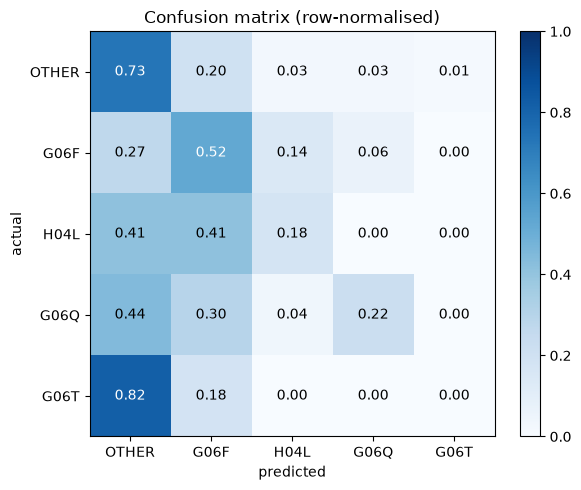

In [36]:
cm = (pred.groupBy("label", "prediction").count().toPandas()
      .pivot(index="label", columns="prediction", values="count").fillna(0))
cm.index = [labels[int(i)] for i in cm.index]
cm.columns = [labels[int(i)] for i in cm.columns]
cm_norm = cm.div(cm.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_norm.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cm.columns)), cm.columns); ax.set_yticks(range(len(cm.index)), cm.index)
for i in range(len(cm.index)):
    for j in range(len(cm.columns)):
        v = cm_norm.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title("Confusion matrix (row-normalised)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

**Interpreting the model.** With a linear model, each class has one coefficient per vocabulary term. The largest positive coefficients are the words that most push a prediction toward that class. Do they make domain sense? With only ~800 training abstracts the word lists are noisy, with some sensible terms (*attack, endpoint* for networking; *purchase, market* for business) mixed with chance words. On the full data they become strikingly clean. Errors tend to fall between *related* domains, which is a useful sanity check.

In [37]:
lr_best = best.stages[-1]
clf_vocab = best.stages[1].vocabulary
coef = lr_best.coefficientMatrix.toArray()
print(f"best params: regParam={lr_best.getRegParam()}, elasticNetParam={lr_best.getElasticNetParam()}\n")
for i, c in enumerate(labels):
    top = np.argsort(coef[i])[::-1][:12]
    print(f"{c} ({SUBCLASS_NAMES.get(c, 'all other subclasses')}):\n    " + ", ".join(clf_vocab[j] for j in top))

best params: regParam=0.1, elasticNetParam=0.0

OTHER (all other subclasses):
    externally, regulate, conversion, embody, however, safe, correctly, conventional, methodology, quickly, accurate, piece
G06F (Digital data processing):
    useful, choose, static, replication, submission, differ, organize, machinereadable, inmemory, diagnose, zoom, unknown
H04L (Digital transmission / networking):
    overlay, traverse, mitigate, wish, uniquely, applicable, attack, endpoint, preprocess, integration, home, nontransitory
G06Q (Business / admin data processing):
    purchase, assignment, thing, prospective, news, examine, late, promote, similarly, latency, market, together
G06T (Image processing):
    approximate, optionally, resolution, visible, multiprocessor, produce, personal, foreground, augment, optical, modeled, graphic


---
## Part 3d – Semantic clustering and search with transformer embeddings

Bag-of-words ignores word order and synonyms. Spark NLP can run **pretrained transformer models** inside Spark. `BertSentenceEmbeddings` (`sent_small_bert_L4_256`, a 4-layer, 256-dimensional BERT, ~40 MB) maps each abstract to one dense vector. Abstracts with similar meaning get nearby vectors even when they share few words.

`EmbeddingsFinisher` converts the annotation into an MLlib `Vector`, so MLlib can take over:
1. `Normalizer` (unit length, so Euclidean distance matches cosine distance)
2. `KMeans` for several *k*, scored by the **silhouette** coefficient (`ClusteringEvaluator`)
3. `BucketedRandomProjectionLSH` for fast approximate **nearest-neighbour search**

Transformers are compute-heavy; on the full data you would embed a sample or use a GPU. Abstracts are truncated to the model's first 128 word-pieces.

In [38]:
bert = (BertSentenceEmbeddings.pretrained("sent_small_bert_L4_256", "en")
        .setInputCols(["document"]).setOutputCol("sentence_embeddings")
        .setMaxSentenceLength(128).setBatchSize(32))
emb_finisher = (EmbeddingsFinisher().setInputCols(["sentence_embeddings"])
                .setOutputCols(["embedding"]).setOutputAsVector(True))
l2 = VectorNormalizer(inputCol="raw_vec", outputCol="features", p=2.0)

embed_model = Pipeline(stages=[document, bert, emb_finisher]).fit(corpus)

emb_sample = patents
embedded = l2.transform(embed_model.transform(emb_sample)
                        .withColumn("raw_vec", F.col("embedding").getItem(0))
                        .select("publication_number", "filing_year", "cpc_subclass", "title", "raw_vec")
                        ).cache()
print(f"{embedded.count():,} abstracts embedded into {len(embedded.first()['features'])}-dim vectors")

sent_small_bert_L4_256 download started this may take some time.
Approximate size to download 40.5 MB
[ | ]sent_small_bert_L4_256 download started this may take some time.
Approximate size to download 40.5 MB
[ | ]Download done! Loading the resource.
[ / ]

2026-11-03 21:38:15.618908: I external/org_tensorflow/tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


[OK!]


1,000 abstracts embedded into 256-dim vectors


In [39]:
sil = ClusteringEvaluator(featuresCol="features", distanceMeasure="cosine")
scores = {}
for k in range(2, 11, 2):
    km = KMeans(k=k, seed=seed, featuresCol="features", maxIter=30).fit(embedded)
    scores[k] = sil.evaluate(km.transform(embedded))
    print(f"k={k:>2}  silhouette = {scores[k]:.3f}")
best_k = max(scores, key=scores.get)
print("best k:", best_k)

k= 2  silhouette = 0.131
k= 4  silhouette = 0.076
k= 6  silhouette = 0.066
k= 8  silhouette = 0.064
k=10  silhouette = 0.063
best k: 2


Silhouette values for text embeddings are usually low (0.05–0.15): technology domains overlap rather than forming crisp clusters. That is itself a finding worth discussing. To **characterise** the clusters, we cross-tabulate them against the CPC labels (which the clustering never saw) and list a few example titles.

In [40]:
km_model = KMeans(k=best_k, seed=seed, featuresCol="features", maxIter=30).fit(embedded)
clustered = km_model.transform(embedded).cache()

w = Window.partitionBy("prediction").orderBy(F.desc("count"))
cluster_profile = (clustered.groupBy("prediction", "cpc_subclass").count()
                   .withColumn("n", F.sum("count").over(Window.partitionBy("prediction")))
                   .withColumn("share", F.round(F.col("count") / F.col("n"), 2))
                   .withColumn("rank", F.row_number().over(w)).filter("rank <= 3")
                   .groupBy("prediction")
                   .agg(F.first("n").alias("n"),
                        F.concat_ws(", ", F.collect_list(F.concat("cpc_subclass", F.lit(" "), "share"))).alias("top CPC (share)"))
                   .orderBy("prediction"))
show(cluster_profile, truncate=False)

examples = (clustered.withColumn("r", F.row_number().over(Window.partitionBy("prediction").orderBy(F.rand(seed))))
            .filter("r <= 3").select("prediction", "title").orderBy("prediction"))
show(examples, 3 * best_k, truncate=90)

+----------+---+-------------------------------+
|prediction|n  |top CPC (share)                |
+----------+---+-------------------------------+
|0         |552|G06F 0.42, G06Q 0.16, H04L 0.16|
|1         |448|G06F 0.18, G06T 0.11, H04N 0.06|
+----------+---+-------------------------------+

+----------+------------------------------------------------------------------------------------------+
|prediction|                                                                                     title|
+----------+------------------------------------------------------------------------------------------+
|         0|                     Time shift configuration management for software product installation|
|         0|System and methods providing sports event related media to internet-enabled devices syn...|
|         0|                                                                           Home assessment|
|         1|                                           Graphical viewer for biomo

### Semantic search: "find patents like this idea"
We embed a free-text query with the *same* Spark NLP pipeline, then ask the LSH model for its approximate nearest neighbours. Locality-sensitive hashing avoids comparing the query with every vector, which matters at millions of documents.

In [41]:
lsh_model = BucketedRandomProjectionLSH(inputCol="features", outputCol="hashes",
                                        bucketLength=1.0, numHashTables=8, seed=seed).fit(embedded)

def search(query, k=5):
    q = embed_model.transform(spark.createDataFrame([(query,)], ["abstract"])).first()["embedding"][0]
    q = DenseVector(q.toArray() / np.linalg.norm(q.toArray()))
    hits = lsh_model.approxNearestNeighbors(embedded, q, k, distCol="distance")
    print(f"Query: {query}")
    show(hits.select("publication_number", "filing_year", "cpc_subclass",
                     F.round(1 - F.col("distance") ** 2 / 2, 3).alias("cosine_sim"), "title"), truncate=80)

search("Automatically detecting fraudulent credit card transactions with machine learning.")
search("Compressing and storing large files across many servers in a data center.")

Query: Automatically detecting fraudulent credit card transactions with machine learning.
+------------------+-----------+------------+----------+--------------------------------------------------------------------------------+
|publication_number|filing_year|cpc_subclass|cosine_sim|                                                                           title|
+------------------+-----------+------------+----------+--------------------------------------------------------------------------------+
|     US-8463237-B1|       2010|        H04M|     0.777|Using communications records to detect unauthorized use of telecommunication ...|
|     US-7805342-B2|       2008|        G06Q|     0.776|Systems and methods for identifying and processing telecommunications billing...|
|    US-10313388-B2|       2018|        H04L|     0.771|                                    Risk assessment using social networking data|
|     US-8700209-B2|       2006|        G16H|     0.767|       Method and system f

---
## Save results and stop Spark

We persist the per-patent outputs (dominant LDA topic) as Parquet so downstream analyses, for example econometric models of firm innovation, can join them on `publication_number`.

In [ ]:
dominant = (doc_topics
            .withColumn("dominant_topic", F.expr("array_position(theta, array_max(theta)) - 1"))
            .withColumn("dominant_topic_share", F.array_max("theta"))
            .select("publication_number", "filing_year", "cpc_subclass", "dominant_topic", "dominant_topic_share"))
dominant.write.mode("overwrite").parquet(output_file_1)
show(spark.read.parquet(output_file_1), 5)

In [ ]:
spark.stop()

---
## Takeaways
* **One API for everything.** Spark NLP annotators and MLlib stages are both Pipeline stages, so preprocessing, feature engineering and models compose, persist (`model.write().save(...)`) and scale together.
* **Domain knowledge beats defaults.** Patent boilerplate swamps generic stop-word lists; a short domain list plus `maxDF` changes the topics dramatically.
* **Pick the representation for the task.** Counts suit LDA, TF-IDF suits linear classifiers, and transformer embeddings capture meaning for clustering and search.
* **Evaluate honestly.** Use held-out perplexity for topic models, stratified sampling plus cross-validation and a chance baseline for classifiers, and silhouette (with caution) for clustering.
* **Know your data's limits.** `limit()` is not a random sample, and right-censoring makes recent patent counts look like a decline.

## Exercises
1. Add five more domain stop words you see in the LDA topics, re-run Part 3a, and compare the topics. Do they get sharper?
2. Replace `LogisticRegression` with `LinearSVC` (wrapped in `OneVsRest`) or `NaiveBayes`. Which wins, and at what training cost?
3. Add `NGramGenerator` to the Spark NLP pipeline so bigrams such as *neural network* become single features. Does classification improve?
4. Train the classifier on BERT embeddings instead of TF-IDF. Is it better with fewer training documents?
5. Set `n_rows = None` (or use `raw.sample(0.05, seed=42)`) and average the topic shares by `filing_year` instead of CPC class: how did the focus of AI patenting shift over 40 years?